In [1]:
import pandas as pd
from IPython.display import display
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df= pd.read_csv(DATA_URL)
print("Kích thước:",df.shape)
print("Các cột:",list(df.columns))
df.info()


Kích thước: (891, 15)
Các cột: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtyp

In [2]:
print("8 dòng đầu của dữ liệu công khai:")
display(df.head(8))

print("Một số dòng có tuổi bị thiếu:")
missing_age_rows = df.index[df["age"].isna()][:5]
display(df.loc[missing_age_rows, ["survived", "pclass", "sex", "age", "embarked", "deck"]])

print("Một số dòng trùng hoàn toàn trên các cột đang có:")
display(df.loc[df.duplicated(keep=False)].head(6))

8 dòng đầu của dữ liệu công khai:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False


Một số dòng có tuổi bị thiếu:


,survived,pclass,sex,age,embarked,deck
5,0,3,male,NaN,Q,NaN
17,1,2,male,NaN,S,NaN
19,1,3,female,NaN,C,NaN
26,0,3,male,NaN,C,NaN
28,1,3,female,NaN,Q,NaN


Một số dòng trùng hoàn toàn trên các cột đang có:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
ANALYSIS = "duplicates"  # Chọn: missingness, duplicates, target_balance, target_leakage, outliers, all

def analyze_titanic(data, analysis):
    missing = data.isna().sum().sort_values(ascending=False)
    duplicate_rows = int(data.duplicated().sum())
    balance = data["survived"].value_counts().sort_index().rename(index={0: "Không sống sót", 1: "Sống sót"})
    alive_matches = data["alive"].eq(data["survived"].map({0: "no", 1: "yes"})).all()
    pclass_matches = data["class"].eq(data["pclass"].map({1: "First", 2: "Second", 3: "Third"})).all()
    q1, q3 = data["fare"].quantile([0.25, 0.75])
    iqr = q3 - q1
    fare_outliers = int(((data["fare"] < q1 - 1.5 * iqr) | (data["fare"] > q3 + 1.5 * iqr)).sum())
    analyses = {
        "missingness": ("Số giá trị thiếu theo cột", missing[missing > 0]),
        "duplicates": ("Số dòng trùng hoàn toàn", duplicate_rows),
        "target_balance": ("Số mẫu theo nhãn survived (0 = không, 1 = có)", balance),
        "target_leakage": ("Cột alive có mã hóa lại survived không?", alive_matches),
        "outliers": ("Tóm tắt tuổi/giá vé và số fare ngoài ngưỡng IQR", data[["age", "fare"]].describe().round(2)),
    }
    if analysis == "all":
        for name, (title, result) in analyses.items():
            print(f"\n{title}\n{result}")
        print("\nclass có khớp pclass không?", pclass_matches)
        return
    if analysis not in analyses:
        raise ValueError(f"Chọn một phân tích trong: {list(analyses)} hoặc 'all'")
    title, result = analyses[analysis]
    print(title)
    print(result)
    if analysis == "duplicates":
        print("\nĐây là trùng trên các cột được công bố, không có khóa hành khách để khẳng định thực sự là cùng một người hay không.")
    if analysis == "target_leakage":
        print("class khớp pclass:", pclass_matches)
        print("alive chỉ là cách viết khác của survived; không được dùng alive làm đặc trưng dự đoán survived.")

analyze_titanic(df, ANALYSIS)

Số dòng trùng hoàn toàn
107

Đây là trùng trên các cột được công bố, không có khóa hành khách để khẳng định thực sự là cùng một người hay không.


In [4]:
# Tạo một bảng phân tích gọn: bỏ cột dư thừa/không cần cho bài minh họa,
# điền Age bằng median và Embarked bằng mode. Không tự xóa các dòng giống nhau.
model_view = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
age_median = model_view["age"].median()
embarked_mode = model_view["embarked"].mode().iloc[0]
model_view["age"] = model_view["age"].fillna(age_median)
model_view["embarked"] = model_view["embarked"].fillna(embarked_mode)

print("Median tuổi dùng trong minh họa:", age_median)
print("Mode cảng dùng trong minh họa:", embarked_mode)
print("Số dòng trước / sau:", len(df), "/", len(model_view))
print("Giá trị thiếu ở các cột được chọn sau xử lý:")
print(model_view.isna().sum())
print("\nCác dòng có Age thiếu — trước xử lý:")
display(df.loc[missing_age_rows, ["survived", "pclass", "sex", "age", "embarked"]])
print("\nCùng các dòng — sau xử lý:")
display(model_view.loc[missing_age_rows, ["survived", "pclass", "sex", "age", "embarked"]])

Median tuổi dùng trong minh họa: 28.0
Mode cảng dùng trong minh họa: S
Số dòng trước / sau: 891 / 891
Giá trị thiếu ở các cột được chọn sau xử lý:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Các dòng có Age thiếu — trước xử lý:


,survived,pclass,sex,age,embarked
5,0,3,male,NaN,Q
17,1,2,male,NaN,S
19,1,3,female,NaN,C
26,0,3,male,NaN,C
28,1,3,female,NaN,Q



Cùng các dòng — sau xử lý:


,survived,pclass,sex,age,embarked
5,0,3,male,28.0,Q
17,1,2,male,28.0,S
19,1,3,female,28.0,C
26,0,3,male,28.0,C
28,1,3,female,28.0,Q


In [5]:
# So sánh thống kê trên đúng các cột bị xử lý và một cột đối chứng.
def numeric_summary(series):
    return {
        "Số giá trị có mặt": int(series.count()),
        "Số giá trị thiếu": int(series.isna().sum()),
        "Mean": series.mean(),
        "Std": series.std(),
        "Median": series.median(),
        "Q1": series.quantile(0.25),
        "Q3": series.quantile(0.75),
    }

summary = pd.DataFrame({
    "Age — trước": numeric_summary(df["age"]),
    "Age — sau": numeric_summary(model_view["age"]),
    "Fare — trước": numeric_summary(df["fare"]),
    "Fare — sau": numeric_summary(model_view["fare"]),
}).T
print("Thống kê mô tả trước / sau (Age được điền median; Fare là cột đối chứng):")
display(summary.round(2))

categories = ["S", "C", "Q", "(Thiếu)"]
embarked_before = df["embarked"].astype("object").fillna("(Thiếu)").value_counts().reindex(categories, fill_value=0)
embarked_after = model_view["embarked"].astype("object").fillna("(Thiếu)").value_counts().reindex(categories, fill_value=0)
embarked_compare = pd.DataFrame({"Trước — số dòng": embarked_before, "Sau — số dòng": embarked_after})
embarked_compare["Trước — %"] = 100 * embarked_before / len(df)
embarked_compare["Sau — %"] = 100 * embarked_after / len(model_view)
print("\nEmbarked trước / sau (mode được điền vào các ô thiếu):")
display(embarked_compare.round(2))

Thống kê mô tả trước / sau (Age được điền median; Fare là cột đối chứng):


,Số giá trị có mặt,Số giá trị thiếu,Mean,Std,Median,Q1,Q3
Age — trước,714.0,177.0,29.70,14.53,28.00,20.12,38.0
Age — sau,891.0,0.0,29.36,13.02,28.00,22.00,35.0
Fare — trước,891.0,0.0,32.20,49.69,14.45,7.91,31.0
Fare — sau,891.0,0.0,32.20,49.69,14.45,7.91,31.0



Embarked trước / sau (mode được điền vào các ô thiếu):


,Trước — số dòng,Sau — số dòng,Trước — %,Sau — %
embarked,,,,
S,644,646,72.28,72.50
C,168,168,18.86,18.86
Q,77,77,8.64,8.64
(Thiếu),2,0,0.22,0.00


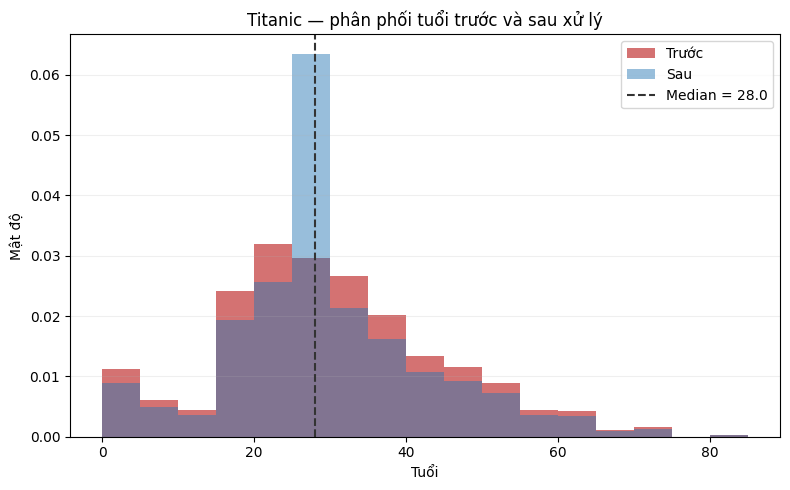

In [6]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5))

# Tuổi trước khi điền thiếu và sau khi điền median.
age_bins = np.arange(0, 86, 5)
ax.hist(df["age"].dropna(), bins=age_bins, density=True, alpha=0.65, label="Trước", color="#BE2727")
ax.hist(model_view["age"], bins=age_bins, density=True, alpha=0.48, label="Sau", color="#2878B5")
ax.axvline(age_median, color="#333333", linestyle="--", label=f"Median = {age_median:.1f}")
ax.set_title("Titanic — phân phối tuổi trước và sau xử lý")
ax.set_xlabel("Tuổi")
ax.set_ylabel("Mật độ")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


,Mean,Std,Q1,Q3
Điền median,29.36,13.02,22.0,35.0
Điền mean,29.70,13.00,22.0,35.0


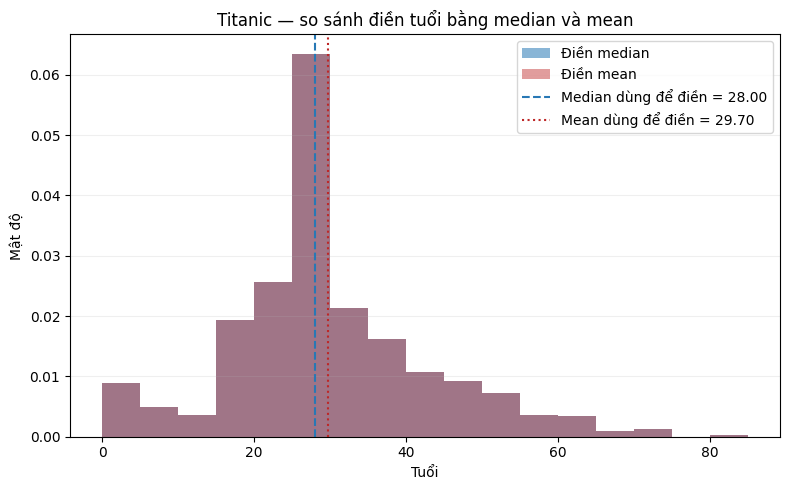

In [7]:
# Tạo bản điền tuổi thiếu bằng mean.
model_view_mean = model_view.copy()
age_mean = df["age"].mean()
model_view_mean["age"] = df["age"].fillna(age_mean)

# So sánh đúng các chỉ số đề yêu cầu.
display(pd.DataFrame({
    "Điền median": numeric_summary(model_view["age"]),
    "Điền mean": numeric_summary(model_view_mean["age"]),
}).T[["Mean", "Std", "Q1", "Q3"]].round(2))

# Tạo hình mới để tránh chồng thêm vào biểu đồ cũ.
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(model_view["age"], bins=age_bins, density=True,
        alpha=0.55, label="Điền median", color="#2878B5")
ax.hist(model_view_mean["age"], bins=age_bins, density=True,
        alpha=0.45, label="Điền mean", color="#BE2727")

ax.axvline(age_median, color="#2878B5", linestyle="--",
           label=f"Median dùng để điền = {age_median:.2f}")
ax.axvline(age_mean, color="#BE2727", linestyle=":",
           label=f"Mean dùng để điền = {age_mean:.2f}")

ax.set_title("Titanic — so sánh điền tuổi bằng median và mean")
ax.set_xlabel("Tuổi")
ax.set_ylabel("Mật độ")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


C1: Dùng mean chưa xác định được mật độ nào nhiều nhất, các cực trị có thể làm mean lệch khỏi phần mật độ nhiều nhất, nên điền vào có thể làm thông tin sai lệch.
Còn median dùng giá trị ở giữa ít bị ảnh hưởng vởi các cực trị.

In [8]:
#2. Điền tuổi theo hạng vé: điền tuổi thiếu bằng median riêng cho từng pclass. So sánh median tuổi giữa các hạng trước và sau; cách này giữ khác biệt giữa nhóm tốt hơn hay kém hơn median chung?
model_view_pclass = model_view.copy()
age_median_by_pclass = df.groupby("pclass")["age"].transform("median")
model_view_pclass["age"] = df["age"].fillna(age_median_by_pclass)

display(pd.DataFrame({
    "Trước xử lý": df.groupby("pclass")["age"].median(),
    "Điền median chung": model_view.groupby("pclass")["age"].median(),
    "Điền median từng hạng": model_view_pclass.groupby("pclass")["age"].median(),
}).round(2))

,Trước xử lý,Điền median chung,Điền median từng hạng
pclass,,,
1,37.0,35.0,37.0
2,29.0,28.0,29.0
3,24.0,28.0,24.0


- Điền median theo từng hạng giữ khác biệt về median giữa các nhóm tốt hơn vì:
  + giữ nguyên median của từng nhóm
  + nếu dùng median chug làm kéo median các nhóm về một mức nào đó


In [9]:
#3. Rà soát giá vé ngoại lệ: tính ngưỡng IQR cho fare, đếm và xem các dòng vượt ngưỡng theo pclass. Đề xuất xử lý; không xóa ngoại lệ chỉ vì chúng nằm ngoài ngưỡng.
fare_q1= df["fare"].quantile(0.25)
fare_q3 =df["fare"].quantile(0.75)
fare_iqr = fare_q3 - fare_q1
fare_lower = fare_q1 - 1.5 * fare_iqr
fare_upper = fare_q3 + 1.5*fare_iqr
fare_outlier_mask = (df["fare"] < fare_lower) | (df["fare"] > fare_upper)
print("Ngưỡng dưới:",round(fare_lower,2))
print("Ngưỡng trên:",round(fare_upper,2))
print("Tổng số dòng ngoài ngưỡng:",fare_outlier_mask.sum())

display(pd.DataFrame({
    "Số dòng ngoại lệ": fare_outlier_mask.groupby(df["pclass"]).sum()
}))

display(df.loc[fare_outlier_mask, ["pclass","fare"]])


Ngưỡng dưới: -26.72
Ngưỡng trên: 65.63
Tổng số dòng ngoài ngưỡng: 116


,Số dòng ngoại lệ
pclass,
1,104
2,5
3,7


,pclass,fare
1,1,71.2833
27,1,263.0000
31,1,146.5208
34,1,82.1708
52,1,76.7292
...,...,...
846,3,69.5500
849,1,89.1042
856,1,164.8667
863,3,69.5500


- Đề xuất xử lý:
  + Kiểm tra các giá vé ngoài ngưỡng bằng cách đối chiếu với pclass và dữ liệu gốc
  + Giữ lại giá vé cao hợp lệ vì chúng phản ánh sự khác biệt giữa các hạng vé
  + Xác minh lại nguồn thông tin xem có bị sai nhập liệu hay ko đúng -> sửa theo nguồn kiểm chứng

In [10]:
#4. Thử tránh rò rỉ: chia dữ liệu thành Train/Test trước, tính median tuổi trên Train rồi dùng median đó cho cả hai tập. So sánh với median tính trên toàn bộ dữ liệu và giải thích vì sao pipeline thực tế phải học cách điền từ Train.
from sklearn.model_selection import train_test_split
train_df,test_df = train_test_split(df,test_size = 0.2, random_state = 42)

train_age_median = train_df["age"].median()
all_age_median = df["age"].median()
print("Median của tuổi trên train:", train_age_median)
print("Median tuổi trên toàn bộ dữ liệu:",all_age_median)

train_df["age"]= train_df["age"].fillna(train_age_median)
test_df["age"] = test_df["age"].fillna(train_age_median)

Median của tuổi trên train: 28.0
Median tuổi trên toàn bộ dữ liệu: 28.0


- Pipeline phải tính median từ Train vì Test được dành để đánh giá trên dữ liệu ko được dùng trong quá trình học.
- Nếu tính median trên toàn bộ dữ liệu thì sẽ dính test làm rò rỉ dữ liệu